<a href="https://www.kaggle.com/code/rellegabrinao/surecure-model?scriptVersionId=360575150" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

# SureCure: product identification and out-of-scope guard

Kaggle notebook for the SureCure PJDSC 2026 entry. Runs top to bottom on a GPU session.

**Running on Google Colab:** Runtime → Change runtime type → T4 GPU, then Run all. The config cell mounts Google Drive (approve the pop-up), finds the dataset in the kagglehub cache or downloads it, and the last cell copies `surecure_outputs.zip` to `MyDrive/SureCure/runs/<RUN_NAME>/`. Keep the tab open: free Colab disconnects idle sessions and deletes `/content`.

**Before you run** (Kaggle)
1. Settings: Accelerator = GPU (T4 or P100), Internet = On (needed for the ImageNet weights and `onnxruntime`).
2. Add data: *Pharmaceutical Drugs and Vitamins Dataset V2* (vencerlanz09). The notebook finds the `Capsure Dataset` folder by itself.
3. Optional: add a dataset of out-of-scope medicine photos (for example CapCure Neozep and Alaxan) and set `OOD_DIR` in the config cell.

**What it produces** (in `/kaggle/working`)
- `metadata.csv`: one row per image (split, class, burst, capture time, size, hashes, role)
- `audit.json`, `lighting_baseline.json`, `metrics.json`, `history.csv`
- `figures/`: confusion matrix, capture-time plot, training curves
- `surecure_model/`: `surecure.onnx`, `labels.json`, `meta.json`, `best.pt`
- `calibration.json`: AdaBN decision, temperature, confidence cut-off for the product list
- `guard_eval.json` and `figures/guard_eval.png`: out-of-scope guard verdict, AUROC per source, baselines
- `golden/`: test images and expected outputs for the Kotlin preprocessing check
- `finetune.json`, `finetune_history.csv`: team-photo fine-tuning (section 6a), before/after accuracy, whether it was kept
- `surecure_outputs.zip`: everything above in one download

**Design rules this notebook enforces**
- Product ID is trained on the synthetic composites only. Real photos are used only for checkpoint selection (dev bursts), conformal calibration (dev bursts) and testing (test bursts).
- Real photos are split by capture burst, never by frame, because frames in one burst are near-duplicates.
- Each class was photographed in its own time window, so a lighting-only baseline is run to show how much lighting alone reveals the class.

## 1. Configuration

In [1]:
import os, io, re, json, math, time, random, hashlib, shutil, zipfile
import sys
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image, ImageOps
import matplotlib
import matplotlib.pyplot as plt

SEED = 42
QUICK = False   # True = 5-minute smoke test (40 synthetic images per class, 1 epoch)
QUICK = os.environ.get("SC_QUICK", str(int(QUICK))) == "1"
EPOCHS = int(os.environ.get("SC_EPOCHS", "1" if QUICK else "10"))
BATCH = 128
LR = 1e-4
WEIGHT_DECAY = 0.05
LABEL_SMOOTHING = 0.1
IMG = 224                  # model input size
CACHE = 256                # size of the preprocessed square images
DEV_BURSTS_PER_CLASS = 4   # real bursts per class held out for selection and calibration
ALPHA = 0.05               # target false-rejection rate of the out-of-scope guard
SYN_VAL_FRAC = 0.10
FEATS_PER_CLASS = 600      # synthetic images per class used to fit the Mahalanobis guard
OOD_DIR = os.environ.get("SC_OOD_DIR", "")   # optional folder of out-of-scope medicine photos
# Extra out-of-scope folders, separated by ":" (each one is scored as its own source)
OOD_DIRS = [p for p in os.environ.get("SC_OOD_DIRS", "").split(":") if p]
OOD_AUTO = os.environ.get("SC_OOD_AUTO", "1") == "1"   # also score every other dataset attached under /kaggle/input
OOD_EXCLUDE = [p for p in os.environ.get("SC_OOD_EXCLUDE", "").split(":") if p]   # name fragments to skip
OOD_MAX_PER_SOURCE = int(os.environ.get("SC_OOD_MAX", "1500"))   # random sample per source, keeps runtime short
AUROC_TARGET = 0.90        # pre-registered target for the out-of-scope guard
AUG_V2 = os.environ.get("SC_AUG_V2", "0") == "1"       # 1 = stronger low-resolution augmentation (run 2), 0 = run 1 settings
# Default switched to 0 after version 5: AUG_V2 + 12 epochs gave real-dev 0.438 vs about 0.52 for run 1 (reverted).
ADABN = os.environ.get("SC_ADABN", "0")                # "auto" = keep AdaBN only if it helps on held-out dev bursts; "1" / "0" force it
# Default switched to "0" after version 5: AdaBN cross-fold gain was -0.084 (rejected by the auto rule).
ADABN_MIN_GAIN = 0.02      # minimum cross-fold dev accuracy gain for "auto" to keep AdaBN
CONF_TARGET = 0.90         # accuracy wanted among predictions the app accepts without the product list
GOLDEN_N = 10              # test images exported for the Kotlin preprocessing check
# Fine-tuning on team photos (section 6a). Runs only when a team-photo folder is found.
TEAM_DIR = os.environ.get("SC_TEAM_DIR", "")              # <product>/<session>/<photo>; "" = auto-detect a folder named like "team"
FT_EPOCHS = int(os.environ.get("SC_FT_EPOCHS", "5"))
FT_LR = float(os.environ.get("SC_FT_LR", "1e-4"))          # lower than LR: adjust the synthetic model, do not retrain it
FT_SYN_RATIO = float(os.environ.get("SC_FT_SYN_RATIO", "1.0"))   # synthetic images per team photo in each epoch (1.0 = 1:1 mix)
FT_BATCH = 64
FT_MIN_GAIN = 0.02         # keep the fine-tuned model only if team-dev accuracy improves by at least this
FT_FREEZE = ("conv1", "bn1", "layer1")   # early layers stay fixed: a few hundred photos are too few to retrain edge filters
GUARD_CAL = os.environ.get("SC_GUARD_CAL", "pooled")      # "pooled" = Capsure dev bursts + one team-dev photo per session; "capsure" = Capsure only
RUN_NAME = os.environ.get("SC_RUN_NAME", time.strftime("run_%Y%m%d_%H%M"))
FILL = (124, 116, 104)     # ImageNet mean, used for letterbox padding
NUM_WORKERS = min(4, os.cpu_count() or 2)

OUT = Path(os.environ.get("SC_OUT", "/kaggle/working"))
CACHE_DIR = OUT / "cache"
FIG_DIR = OUT / "figures"
MODEL_DIR = OUT / "surecure_model"
# Google Colab: work on the fast local disk, then copy the results to Google Drive at the end.
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB and "SC_OUT" not in os.environ:
    OUT = Path("/content/surecure_out")
    CACHE_DIR = OUT / "cache"
    FIG_DIR = OUT / "figures"
    MODEL_DIR = OUT / "surecure_model"
DRIVE_DIR = os.environ.get("SC_DRIVE_DIR", "/content/drive/MyDrive/SureCure/runs" if IN_COLAB else "")
if IN_COLAB and DRIVE_DIR:
    try:
        from google.colab import drive
        drive.mount("/content/drive")   # asks for permission once, at the start, while you are still watching
    except Exception as e:
        print("Drive not mounted, results stay in", OUT, "|", e)
        DRIVE_DIR = ""
for d in (CACHE_DIR, FIG_DIR, MODEL_DIR):
    d.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)

SPLIT_DIRS = {"Train Image": "train", "Val": "val", "Test": "test"}
LABEL_FIX = {"Tuseran": "Tuseran_Forte"}   # Train uses "Tuseran", Val/Test use "Tuseran_Forte"
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}


def find_root():
    env = os.environ.get("SC_DATA_ROOT")
    if env:
        return Path(env)
    # Walk /kaggle/input a few levels deep looking for "Capsure Dataset".
    base = Path("/kaggle/input")
    if base.exists():
        frontier = [base]
        for _ in range(5):
            nxt = []
            for p in frontier:
                try:
                    for c in p.iterdir():
                        if c.is_dir():
                            if c.name == "Capsure Dataset":
                                return c
                            nxt.append(c)
                except PermissionError:
                    pass
            frontier = nxt
    # Colab and other machines: kagglehub keeps downloads in ~/.cache/kagglehub
    kh = Path.home() / ".cache" / "kagglehub"
    if kh.exists():
        hit = next((x for x in kh.rglob("Capsure Dataset") if x.is_dir()), None)
        if hit is not None:
            return hit
    import kagglehub
    p = Path(kagglehub.dataset_download("vencerlanz09/pharmaceutical-drugs-and-vitamins-dataset-v2"))
    return next(x for x in p.rglob("Capsure Dataset") if x.is_dir())


ROOT = find_root()
print("Data root:", ROOT)
print("Quick mode:", QUICK, "| epochs:", EPOCHS, "| workers:", NUM_WORKERS)
print("Run:", RUN_NAME, "| AUG_V2:", AUG_V2, "| ADABN:", ADABN)
print("Platform:", "Colab" if IN_COLAB else "Kaggle/other", "| outputs:", OUT, "| Drive copy:", DRIVE_DIR or "off")

# Partial downloads fail silently later, so count files now (expected: about 40,000 synthetic, 11,000 real).
n_files = {s: sum(1 for p in (ROOT / s).rglob("*") if p.suffix.lower() in IMG_EXT) if (ROOT / s).exists() else 0
           for s in SPLIT_DIRS}
print("Image files per split folder:", n_files)
if n_files.get("Train Image", 0) < 30000 or n_files.get("Val", 0) + n_files.get("Test", 0) < 8000:
    print("WARNING: dataset looks incomplete. Re-download with kagglehub.dataset_download("
          "'vencerlanz09/pharmaceutical-drugs-and-vitamins-dataset-v2', force_download=True) and rerun this cell.")

Data root: /kaggle/input/datasets/vencerlanz09/pharmaceutical-drugs-and-vitamins-dataset-v2/Capsure Dataset
Quick mode: False | epochs: 10 | workers: 4
Run: run_20261020_2232 | AUG_V2: False | ADABN: 0
Platform: Kaggle/other | outputs: /kaggle/working | Drive copy: off
Image files per split folder: {'Train Image': 40000, 'Val': 9103, 'Test': 2000}


## 2. Index, preprocess and hash every image

For each file this step:
- applies the EXIF rotation (the real photos are stored sideways with orientation flag 6);
- letterboxes it to a square with the ImageNet mean color and resizes it to 256 px, so real and synthetic images share one geometry;
- records the MD5 of the file, a 64-bit difference hash (real photos only) for near-duplicate detection, and simple lighting features (real photos only).

Burst ID = the `YYYYMMDD_HHMMSS` prefix of a real photo's file name. Frames in one burst are near-duplicates of one scene.

In [2]:
NAME_RE = re.compile(r"(\d{8})_(\d{6})(?:_(\d+))?")   # searched anywhere in the name


def letterbox(img, fill=FILL):
    w, h = img.size
    s = max(w, h)
    canvas = Image.new("RGB", (s, s), fill)
    canvas.paste(img, ((s - w) // 2, (s - h) // 2))
    return canvas


def dhash(img):
    g = img.convert("L").resize((9, 8), Image.BILINEAR)
    a = np.asarray(g, dtype=np.int16)
    bits = (a[:, 1:] > a[:, :-1]).flatten()
    return "%016x" % int("".join("1" if b else "0" for b in bits), 2)


def lighting_features(img):
    a = np.asarray(img.convert("RGB").resize((64, 64), Image.BILINEAR), dtype=np.float32) / 255.0
    mean = a.reshape(-1, 3).mean(0)
    std = a.reshape(-1, 3).std(0)
    lum = 0.299 * a[..., 0] + 0.587 * a[..., 1] + 0.114 * a[..., 2]
    hist, _ = np.histogram(lum, bins=16, range=(0.0, 1.0), density=True)
    return np.concatenate([mean, std, hist / 16.0]).tolist()


def process(job):
    src, dst, is_real = job
    data = Path(src).read_bytes()
    out = {"md5": hashlib.md5(data).hexdigest()}
    img = Image.open(io.BytesIO(data))
    img = ImageOps.exif_transpose(img).convert("RGB")
    out["width"], out["height"] = img.size
    if is_real:
        out["dhash"] = dhash(img)
        out["light"] = lighting_features(img)
    if not Path(dst).exists():
        Path(dst).parent.mkdir(parents=True, exist_ok=True)
        letterbox(img).resize((CACHE, CACHE), Image.BILINEAR).save(dst, quality=95)
    return out


rows = []
for split_dir, split in SPLIT_DIRS.items():
    sdir = ROOT / split_dir
    if not sdir.exists():
        print("Missing split folder:", sdir)
        continue
    for cdir in sorted(p for p in sdir.iterdir() if p.is_dir()):
        cls = LABEL_FIX.get(cdir.name, cdir.name)
        files = sorted(p for p in cdir.iterdir() if p.suffix.lower() in IMG_EXT)
        if QUICK and split == "train":
            files = files[:40]
        for f in files:
            m = NAME_RE.search(f.stem)
            is_real = split != "train"
            if m:
                burst, frame = f"{m.group(1)}_{m.group(2)}", int(m.group(3) or 0)
                hhmm = f"{m.group(2)[:2]}:{m.group(2)[2:4]}"
            elif is_real:
                # No timestamp in the name: treat the file as its own one-frame burst.
                burst, frame, hhmm = f"nots_{cls}_{f.stem}", 0, None
            else:
                burst, frame, hhmm = None, None, None
            rows.append({
                "path": str(f),
                "split": split,
                "source": "synthetic" if split == "train" else "real",
                "cls_folder": cdir.name,
                "cls": cls,
                "burst": burst,
                "frame": frame,
                "capture_hhmm": hhmm,
                "cache": str(CACHE_DIR / split / cls / (f.stem + ".jpg")),
            })
meta = pd.DataFrame(rows)
print(meta.groupby(["split", "source"]).size())
nots = meta[(meta["source"] == "real") & meta["capture_hhmm"].isna()]
print(f"Real files without a timestamp in the name: {len(nots)}")
if len(nots):
    print(nots.groupby("cls").size().to_string())
    print("Examples:", [Path(p).name for p in nots["path"].head(10)])

t0 = time.time()
jobs = list(zip(meta["path"], meta["cache"], meta["source"] == "real"))
# Threads by default: a fork-based process pool can deadlock on Python 3.12+ (Kaggle runs 3.13).
USE_THREADS = os.environ.get("SC_THREADS", "1") == "1"
if USE_THREADS:
    from concurrent.futures import ThreadPoolExecutor
    results = []
    with ThreadPoolExecutor(max_workers=16) as ex:
        for i, r in enumerate(ex.map(process, jobs)):
            results.append(r)
            if i % 2000 == 0 or i == len(jobs) - 1:
                print(f"  {i + 1}/{len(jobs)} images, {time.time() - t0:.0f} s", flush=True)
else:
    ctx = mp.get_context("fork")
    with ProcessPoolExecutor(max_workers=NUM_WORKERS, mp_context=ctx) as ex:
        results = list(ex.map(process, jobs, chunksize=64))
res = pd.DataFrame(results)
meta = pd.concat([meta.reset_index(drop=True), res], axis=1)
print(f"Processed {len(meta)} images in {time.time() - t0:.0f} s")

split  source   
test   real          2000
train  synthetic    40000
val    real          9103
dtype: int64
Real files without a timestamp in the name: 0
  1/51103 images, 1 s
  2001/51103 images, 11 s
  4001/51103 images, 20 s
  6001/51103 images, 30 s
  8001/51103 images, 39 s
  10001/51103 images, 48 s
  12001/51103 images, 56 s
  14001/51103 images, 65 s
  16001/51103 images, 74 s
  18001/51103 images, 82 s
  20001/51103 images, 91 s
  22001/51103 images, 100 s
  24001/51103 images, 108 s
  26001/51103 images, 117 s
  28001/51103 images, 126 s
  30001/51103 images, 134 s
  32001/51103 images, 143 s
  34001/51103 images, 152 s
  36001/51103 images, 161 s
  38001/51103 images, 169 s
  40001/51103 images, 178 s
  42001/51103 images, 186 s
  44001/51103 images, 195 s
  46001/51103 images, 203 s
  48001/51103 images, 212 s
  50001/51103 images, 221 s
  51103/51103 images, 226 s
Processed 51103 images in 226 s


## 3. Audit

Counts per split and class, exact duplicates across splits, bursts per class, and the capture-time window of each class.

split          test  train  val
cls                            
Ascozin         100   2000  438
Bioflu          100   2000  440
Biogesic        100   2000  500
Bonamine        100   2000  440
Buscopan        100   2000  440
DayZinc         100   2000  444
Decolgen        100   2000  440
Flanax          100   2000  441
Imodium         100   2000  470
Lactezin        100   2000  500
Lagundi         100   2000  440
Midol           100   2000  439
Myra_E          100   2000  471
Neurogen_E      100   2000  411
Omeprazole      100   2000  440
Rinityn         100   2000  440
Rogin_E         100   2000  440
Sinecod         100   2000  440
Tempra          100   2000  499
Tuseran_Forte   100   2000  530

Totals: {'train': 40000, 'val': 9103, 'test': 2000}

Exact duplicate groups: 0 | spanning more than one split: 0

Bursts per class: {'Ascozin': 18, 'Bioflu': 18, 'Biogesic': 20, 'Bonamine': 18, 'Buscopan': 18, 'DayZinc': 20, 'Decolgen': 18, 'Flanax': 19, 'Imodium': 19, 'Lactezin': 20, 'Lagundi'

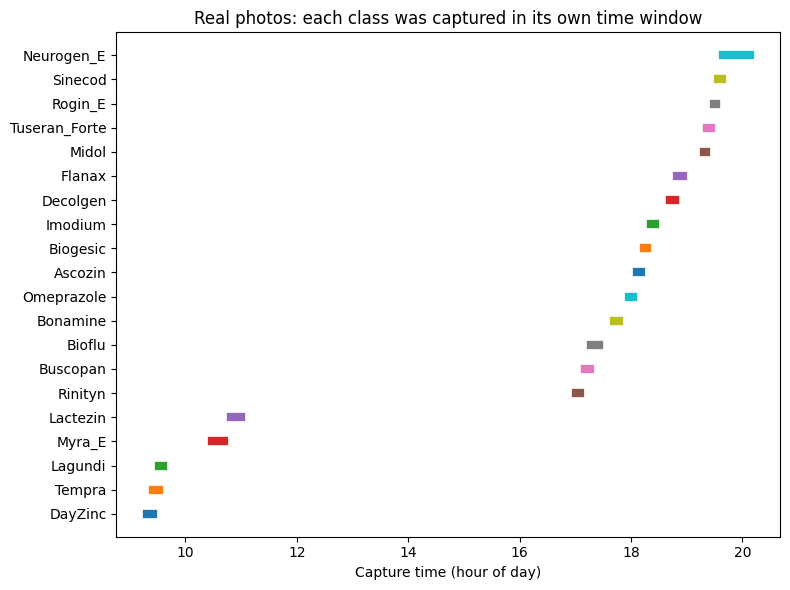

3984

In [3]:
CLASSES = sorted(meta["cls"].unique())
C = len(CLASSES)
CLS2IDX = {c: i for i, c in enumerate(CLASSES)}
meta["y"] = meta["cls"].map(CLS2IDX)

counts = meta.pivot_table(index="cls", columns="split", values="path", aggfunc="count").fillna(0).astype(int)
print(counts)
print("\nTotals:", meta["split"].value_counts().to_dict())

# Exact duplicates (same bytes)
dup = meta.groupby("md5").agg(n=("path", "size"), splits=("split", lambda s: ",".join(sorted(set(s)))))
dup = dup[dup["n"] > 1]
cross = dup[dup["splits"].str.contains(",")]
print(f"\nExact duplicate groups: {len(dup)} | spanning more than one split: {len(cross)}")

real = meta[meta["source"] == "real"].copy()

# Bursts shared between Val and Test (frame-level split leakage)
bv = real.groupby(["cls", "split"])["burst"].apply(set).unstack()
shared = {c: len(bv.loc[c, "val"] & bv.loc[c, "test"]) for c in bv.index
          if isinstance(bv.loc[c, "val"], set) and isinstance(bv.loc[c, "test"], set)}
bursts_per_class = real.groupby("cls")["burst"].nunique()
print("\nBursts per class:", bursts_per_class.to_dict())
print("Bursts shared by Val and Test per class:", shared)

# Near-duplicate clusters inside each burst (Hamming distance <= 6 on the 64-bit dHash)
def hamming(a, b):
    return bin(int(a, 16) ^ int(b, 16)).count("1")

cluster_ids = {}
for burst, g in real.sort_values("frame").groupby("burst"):
    reps = []
    for idx, h in zip(g.index, g["dhash"]):
        for k, (rh, cid) in enumerate(reps):
            if hamming(h, rh) <= 6:
                cluster_ids[idx] = cid
                break
        else:
            cid = f"{burst}#{len(reps)}"
            reps.append((h, cid))
            cluster_ids[idx] = cid
real["dup_cluster"] = pd.Series(cluster_ids)
meta.loc[real.index, "dup_cluster"] = real["dup_cluster"]
print(f"Real frames: {len(real)} | near-duplicate clusters: {real['dup_cluster'].nunique()} | bursts: {real['burst'].nunique()}")

# Capture-time window per class (the lighting confound)
win = (real.dropna(subset=["capture_hhmm"]).groupby("cls")["capture_hhmm"]
       .agg(["min", "max"]).sort_values("min"))
print("\nCapture window per class:")
print(win.to_string())

fig, ax = plt.subplots(figsize=(8, 6))
for i, (c, r) in enumerate(win.iterrows()):
    t0_ = int(r["min"][:2]) * 60 + int(r["min"][3:])
    t1_ = int(r["max"][:2]) * 60 + int(r["max"][3:])
    ax.plot([t0_ / 60, max(t1_, t0_ + 1) / 60], [i, i], lw=6)
ax.set_yticks(range(len(win)))
ax.set_yticklabels(win.index)
ax.set_xlabel("Capture time (hour of day)")
ax.set_title("Real photos: each class was captured in its own time window")
fig.tight_layout()
fig.savefig(FIG_DIR / "capture_windows.png", dpi=150)
plt.show()

audit = {
    "counts": counts.to_dict(),
    "totals": meta["split"].value_counts().to_dict(),
    "exact_duplicate_groups": int(len(dup)),
    "exact_duplicates_across_splits": int(len(cross)),
    "bursts_per_class": bursts_per_class.to_dict(),
    "val_test_shared_bursts": shared,
    "real_frames": int(len(real)),
    "near_duplicate_clusters": int(real["dup_cluster"].nunique()),
    "capture_window": win.to_dict(orient="index"),
    "real_size_counts": {f"{w}x{h}": int(n) for (w, h), n in
                         real.groupby(["width", "height"]).size().sort_values(ascending=False).head(5).items()},
}
(OUT / "audit.json").write_text(json.dumps(audit, indent=2, default=str))

## 4. Splits

- **Synthetic** (Train Image folder): 90% train, 10% validation (random).
- **Real** (Val and Test folders merged): per class, `DEV_BURSTS_PER_CLASS` bursts become **dev** (checkpoint choice and conformal calibration), the rest become **test**. A burst never appears in two roles.
- **Calibration set**: one random frame per dev burst, pooled across classes (n = bursts, not frames, so the conformal guarantee is not inflated by near-duplicates).

In [4]:
rng = np.random.default_rng(SEED)
meta["role"] = None

syn_idx = np.array(meta.index[meta["source"] == "synthetic"], copy=True)
rng.shuffle(syn_idx)
n_val = int(len(syn_idx) * SYN_VAL_FRAC)
meta.loc[syn_idx[:n_val], "role"] = "syn_val"
meta.loc[syn_idx[n_val:], "role"] = "syn_train"

meta["is_cal"] = False
for c in CLASSES:
    bursts = sorted(meta.loc[(meta["source"] == "real") & (meta["cls"] == c), "burst"].unique())
    rng.shuffle(bursts)
    k = min(DEV_BURSTS_PER_CLASS, max(1, len(bursts) // 3))
    dev, test = set(bursts[:k]), set(bursts[k:])
    real_c = (meta["source"] == "real") & (meta["cls"] == c)
    meta.loc[real_c & meta["burst"].isin(dev), "role"] = "real_dev"
    meta.loc[real_c & meta["burst"].isin(test), "role"] = "real_test"
    for b in dev:
        idx = meta.index[real_c & (meta["burst"] == b)].to_numpy()
        meta.loc[rng.choice(idx), "is_cal"] = True

print(meta["role"].value_counts())
print("Calibration frames (one per dev burst):", int(meta["is_cal"].sum()))
assert meta["role"].notna().all()
assert not (set(meta.loc[meta.role == "real_dev", "burst"]) & set(meta.loc[meta.role == "real_test", "burst"]))
meta.drop(columns=["light"]).to_csv(OUT / "metadata.csv", index=False)

role
syn_train    36000
real_test     8724
syn_val       4000
real_dev      2379
Name: count, dtype: int64
Calibration frames (one per dev burst): 80


## 5. Lighting-only baseline

A logistic regression on 22 lighting numbers per real photo (mean and spread of R, G, B and a 16-bin brightness histogram), cross-validated by burst. Chance is 1/20 = 5%. A score far above chance means lighting alone identifies the class in the real photos, so any model fine-tuned on these photos could learn lighting instead of packaging. This is why product ID is trained on synthetic images only.

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GroupKFold, cross_val_predict


def wilson(k, n, z=1.96):
    if n == 0:
        return (float("nan"), float("nan"))
    p = k / n
    den = 1 + z * z / n
    centre = (p + z * z / (2 * n)) / den
    half = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (centre - half, centre + half)


R = meta[meta["source"] == "real"]
X = np.array(R["light"].tolist(), dtype=np.float32)
y = R["y"].to_numpy()
groups = R["burst"].to_numpy()
n_splits = min(5, len(np.unique(groups)))
clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))
pred = cross_val_predict(clf, X, y, groups=groups, cv=GroupKFold(n_splits=n_splits))
acc = float((pred == y).mean())

# Burst-level: majority vote of frames in each burst
bdf = pd.DataFrame({"burst": groups, "y": y, "p": pred})
bvote = bdf.groupby("burst").agg(y=("y", "first"), p=("p", lambda s: s.mode().iloc[0]))
bk, bn = int((bvote["y"] == bvote["p"]).sum()), len(bvote)
lighting = {
    "frame_accuracy": acc,
    "burst_accuracy": bk / bn,
    "burst_accuracy_wilson95": wilson(bk, bn),
    "n_bursts": bn,
    "chance": 1 / C,
}
print(json.dumps(lighting, indent=2))
(OUT / "lighting_baseline.json").write_text(json.dumps(lighting, indent=2))

{
  "frame_accuracy": 0.1291542826263172,
  "burst_accuracy": 0.14133333333333334,
  "burst_accuracy_wilson95": [
    0.10970213512442653,
    0.18023856832524746
  ],
  "n_bursts": 375,
  "chance": 0.05
}


205

## 6. Product identification: ResNet-18 trained on synthetic images

Augmentations push synthetic images toward the look of the real phone photos: random letterbox bars, crops, perspective, color shifts, blur, down-and-up scaling (the real photos are only 300 × 135 px) and JPEG artifacts. No horizontal flip, because mirrored packaging text does not occur in real photos.

In [6]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import transforms as T

torch.manual_seed(SEED)
torch.backends.cudnn.benchmark = True
device = "cuda" if torch.cuda.is_available() else "cpu"
use_amp = device == "cuda"
print("Device:", device, "| torch", torch.__version__, "| torchvision", torchvision.__version__)

MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]


class RandomLetterbox:
    # Crop a random narrow vertical strip and pad it back to a square, like the portrait real photos.
    def __init__(self, p=0.5, min_aspect=0.4):
        self.p, self.min_aspect = p, min_aspect

    def __call__(self, img):
        if random.random() > self.p:
            return img
        w, h = img.size
        a = random.uniform(self.min_aspect, 1.0)
        nw = max(8, int(w * a))
        x0 = random.randint(0, w - nw)
        return letterbox(img.crop((x0, 0, x0 + nw, h))).resize((w, h), Image.BILINEAR)


class RandomDownUp:
    def __init__(self, p=0.5, lo=80, hi=160):
        self.p, self.lo, self.hi = p, lo, hi

    def __call__(self, img):
        if random.random() > self.p:
            return img
        s = random.randint(self.lo, self.hi)
        return img.resize((s, s), Image.BILINEAR).resize(img.size, Image.BILINEAR)


class RandomJPEG:
    def __init__(self, p=0.5, lo=30, hi=90):
        self.p, self.lo, self.hi = p, lo, hi

    def __call__(self, img):
        if random.random() > self.p:
            return img
        buf = io.BytesIO()
        img.save(buf, format="JPEG", quality=random.randint(self.lo, self.hi))
        buf.seek(0)
        return Image.open(buf).convert("RGB")


train_tf = T.Compose([
    # AUG_V2 values first, run 1 values after "else" (kept so either run can be reproduced)
    RandomLetterbox(0.8 if AUG_V2 else 0.5),
    T.RandomResizedCrop(IMG, scale=(0.3, 1.0) if AUG_V2 else (0.5, 1.0), ratio=(0.75, 1.33)),
    T.RandomApply([T.RandomPerspective(distortion_scale=0.2, p=1.0)], p=0.3),
    T.ColorJitter(0.3, 0.3, 0.3, 0.05),
    T.RandomApply([T.GaussianBlur(5, sigma=(0.1, 2.0))], p=0.3),
    # Real photos are about 300 x 135 px, so a pack covers far fewer than 160 px; AUG_V2 goes down to 40 px.
    RandomDownUp(0.5, lo=40, hi=100) if AUG_V2 else RandomDownUp(0.5),
    RandomJPEG(0.5),
    T.ToTensor(),
    T.Normalize(MEAN, STD),
])
eval_tf = T.Compose([T.Resize((IMG, IMG)), T.ToTensor(), T.Normalize(MEAN, STD)])


class ImgDS(Dataset):
    def __init__(self, df, tf):
        self.paths = df["cache"].tolist()
        self.ys = df["y"].astype(int).tolist()
        self.tf = tf

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        return self.tf(Image.open(self.paths[i]).convert("RGB")), self.ys[i]


def loader(df, tf, shuffle, bs=BATCH):
    return DataLoader(ImgDS(df, tf), batch_size=bs, shuffle=shuffle, num_workers=NUM_WORKERS,
                      pin_memory=(device == "cuda"), persistent_workers=NUM_WORKERS > 0,
                      drop_last=shuffle)


syn_train = meta[meta.role == "syn_train"]
syn_val = meta[meta.role == "syn_val"]
real_dev = meta[meta.role == "real_dev"]
real_test = meta[meta.role == "real_test"]
dl_train = loader(syn_train, train_tf, True)
dl_synval = loader(syn_val, eval_tf, False)
dl_dev = loader(real_dev, eval_tf, False)
print(len(syn_train), "train |", len(syn_val), "syn val |", len(real_dev), "real dev |", len(real_test), "real test")

Device: cuda | torch 2.11.0+cu128 | torchvision 0.26.0+cu128
36000 train | 4000 syn val | 2379 real dev | 8724 real test


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 223MB/s]


{'epoch': 1, 'train_loss': 2.14090763165009, 'syn_val_acc': 0.90325, 'real_dev_acc': 0.38083228247162676, 'seconds': 166.21976232528687}
{'epoch': 2, 'train_loss': 0.9724612980550719, 'syn_val_acc': 0.9545, 'real_dev_acc': 0.4098360655737705, 'seconds': 151.78910398483276}
{'epoch': 3, 'train_loss': 0.8778440939574055, 'syn_val_acc': 0.96225, 'real_dev_acc': 0.44766708701134933, 'seconds': 151.74364948272705}
{'epoch': 4, 'train_loss': 0.8323573826470834, 'syn_val_acc': 0.96725, 'real_dev_acc': 0.4598570828079025, 'seconds': 151.3892364501953}
{'epoch': 5, 'train_loss': 0.8086194275112762, 'syn_val_acc': 0.9735, 'real_dev_acc': 0.4548129466162253, 'seconds': 151.89128732681274}
{'epoch': 6, 'train_loss': 0.7871462804566923, 'syn_val_acc': 0.9765, 'real_dev_acc': 0.4665825977301387, 'seconds': 153.5004267692566}
{'epoch': 7, 'train_loss': 0.7754172723064219, 'syn_val_acc': 0.98075, 'real_dev_acc': 0.4636401849516604, 'seconds': 154.32467079162598}
{'epoch': 8, 'train_loss': 0.7674697122

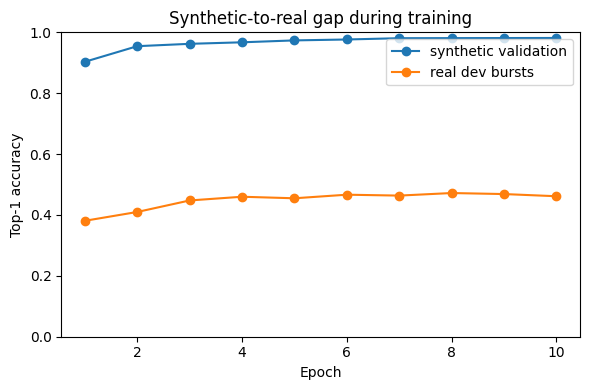

In [7]:
model = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.IMAGENET1K_V1)
model.fc = nn.Linear(model.fc.in_features, C)
model = model.to(device)

opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
steps = EPOCHS * len(dl_train)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=LR, total_steps=steps, pct_start=0.1)
crit = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)
try:
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
except (AttributeError, TypeError):
    scaler = torch.cuda.amp.GradScaler(enabled=use_amp)


@torch.no_grad()
def predict(m, dl):
    m.eval()
    out = []
    for x, _ in dl:
        with torch.autocast(device_type=device, dtype=torch.float16, enabled=use_amp):
            out.append(m(x.to(device, non_blocking=True)).float().cpu())
    return torch.cat(out)


history, best = [], (-1.0, None)
for ep in range(EPOCHS):
    model.train()
    t0, tot, n = time.time(), 0.0, 0
    for x, yb in dl_train:
        x, yb = x.to(device, non_blocking=True), yb.to(device, non_blocking=True)
        opt.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device, dtype=torch.float16, enabled=use_amp):
            loss = crit(model(x), yb)
        scaler.scale(loss).backward()
        scaler.step(opt)
        scaler.update()
        sched.step()
        tot += loss.item() * len(yb)
        n += len(yb)
    syn_acc = float((predict(model, dl_synval).argmax(1).numpy() == syn_val["y"].to_numpy()).mean())
    dev_acc = float((predict(model, dl_dev).argmax(1).numpy() == real_dev["y"].to_numpy()).mean())
    history.append({"epoch": ep + 1, "train_loss": tot / max(n, 1), "syn_val_acc": syn_acc,
                    "real_dev_acc": dev_acc, "seconds": time.time() - t0})
    print(history[-1])
    if dev_acc > best[0]:
        best = (dev_acc, ep + 1)
        torch.save(model.state_dict(), MODEL_DIR / "best.pt")

pd.DataFrame(history).to_csv(OUT / "history.csv", index=False)
model.load_state_dict(torch.load(MODEL_DIR / "best.pt", map_location=device))
print("Best epoch by real-dev accuracy:", best[1], "| dev acc:", round(best[0], 4))

h = pd.DataFrame(history)
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(h["epoch"], h["syn_val_acc"], marker="o", label="synthetic validation")
ax.plot(h["epoch"], h["real_dev_acc"], marker="o", label="real dev bursts")
ax.set_xlabel("Epoch"); ax.set_ylabel("Top-1 accuracy"); ax.set_ylim(0, 1); ax.legend()
ax.set_title("Synthetic-to-real gap during training")
fig.tight_layout(); fig.savefig(FIG_DIR / "training_curves.png", dpi=150); plt.show()

## 6a. Fine-tune on team photos (runs only when team photos are attached)

Synthetic-only training reaches about 98% on synthetic validation but only 40 to 52% on real photos (runs 1 to 5). Neither stronger augmentation nor AdaBN closed that gap, so real phone photos of the 20 packs are the remaining lever.

**Folder layout** (a Kaggle dataset, a folder on Google Drive, or the path in `SC_TEAM_DIR`): `<product>/<session>/<photo>.jpg`, with product folder names as in `labels.json` (for example `Myra_E`, `Tuseran_Forte`; case, spaces and dashes are ignored), 6 sessions per product, about 6 photos per session. Prepare it with `scripts/prepare_team_photos.py`.

**Splits by session, never by photo.** Photos in one session share lighting, background and pose, so splitting them across roles would leak. Per product, sessions are shuffled with `SEED`: 4 train, 1 dev, 1 test.

**Training.** Fine-tuning continues from the synthetic checkpoint at a lower learning rate (`FT_LR`), with the first layers frozen (`FT_FREEZE`). Each epoch mixes all team-train photos with an equal number of fresh synthetic images (`FT_SYN_RATIO`), so the model keeps the variety it learned from synthetic data.

**Selection and safeguard.** The epoch with the best team-dev accuracy is kept, but only if it beats the synthetic-only model by at least `FT_MIN_GAIN`; otherwise the synthetic-only model is kept.

**Checks reported:**
- a lighting-only baseline on the team photos, grouped by session (a high score means lighting differs by product, as in Capsure);
- exact duplicates of Capsure files;
- team-test accuracy before and after fine-tuning, per photo and per product (majority vote over its test session).

Team-test is reported, never used for any choice.

In [8]:
from concurrent.futures import ThreadPoolExecutor


def norm_name(s_):
    return re.sub(r"[^a-z0-9]", "", s_.lower())


CLS_BY_NORM = {norm_name(c): c for c in CLASSES}
for k_, v_ in LABEL_FIX.items():
    CLS_BY_NORM[norm_name(k_)] = v_


def iter_dirs(base, depth=4):
    # Breadth-first walk over folders only, skipping the Capsure dataset (51,000 files).
    frontier = [base]
    for _ in range(depth):
        nxt = []
        for p_ in frontier:
            try:
                for c_ in p_.iterdir():
                    if c_.is_dir() and c_.name != "Capsure Dataset":
                        yield c_
                        nxt.append(c_)
            except (PermissionError, OSError):
                pass
        frontier = nxt


def find_team_dir():
    if TEAM_DIR:
        return Path(TEAM_DIR) if Path(TEAM_DIR).exists() else None
    for base in [Path("/kaggle/input"), Path.home() / ".cache" / "kagglehub", Path("/content/drive/MyDrive/SureCure")]:
        if not base.exists():
            continue
        for d in iter_dirs(base, depth=6):
            if "team" in str(d).lower():          # the folder or one of its parents is named like "team"
                kids = {norm_name(k.name) for k in d.iterdir() if k.is_dir()}
                if len(kids & set(CLS_BY_NORM)) >= 5:
                    return d
    return None


_found = find_team_dir()
if TEAM_DIR and _found is None:
    print("WARNING: SC_TEAM_DIR does not exist:", TEAM_DIR)
TEAM_DIR = str(_found) if _found is not None else ""
HAVE_TEAM = bool(TEAM_DIR)
team = pd.DataFrame(columns=["path", "cls", "y", "session", "cache", "group", "role"])
FT_REPORT = {"used": False}

if not HAVE_TEAM:
    print("No team-photo folder found: fine-tuning is skipped. Attach one or set SC_TEAM_DIR.")
else:
    rows_t, skipped = [], []
    for pdir in sorted(p_ for p_ in Path(TEAM_DIR).iterdir() if p_.is_dir()):
        cls = CLS_BY_NORM.get(norm_name(pdir.name))
        if cls is None:
            skipped.append(pdir.name)
            continue
        for f in sorted(p_ for p_ in pdir.rglob("*") if p_.suffix.lower() in IMG_EXT):
            rel = f.relative_to(pdir)
            rows_t.append({"path": str(f), "cls": cls, "y": CLS2IDX[cls],
                           "session": rel.parts[0] if len(rel.parts) > 1 else None,
                           "cache": str(CACHE_DIR / "team" / cls / (hashlib.md5(str(f).encode()).hexdigest()[:12] + ".jpg"))})
    team = pd.DataFrame(rows_t)
    if skipped:
        print("WARNING: folders that match no product were skipped:", skipped)
    if team.empty:
        print("WARNING: the team folder has no usable photos; fine-tuning is skipped.")
        HAVE_TEAM = False

if HAVE_TEAM:
    nos = team["session"].isna()
    if nos.any():
        print(f"WARNING: {int(nos.sum())} photos sit directly in a product folder. Sessions are assigned by file order "
              "(6 chunks), which only works if file names follow capture time. Prefer <product>/<session>/ folders.")
        for c, g in team[nos].groupby("cls"):
            for j, idx in enumerate(np.array_split(g.sort_values("path").index.to_numpy(), 6)):
                team.loc[idx, "session"] = f"chunk{j}"
    team["group"] = team["cls"] + "/" + team["session"].astype(str)

    with ThreadPoolExecutor(max_workers=16) as ex:
        res_t = list(ex.map(process, zip(team["path"], team["cache"], [True] * len(team))))
    team = pd.concat([team.reset_index(drop=True), pd.DataFrame(res_t)], axis=1)

    # Session-level split per product: 4 train, 1 dev, 1 test
    rng_t = np.random.default_rng(SEED)
    team["role"] = "team_train"
    too_few = []
    for c, g in team.groupby("cls"):
        sess = sorted(g["session"].unique())
        rng_t.shuffle(sess)
        if len(sess) >= 3:
            team.loc[g.index[(g["session"] == sess[-1]).to_numpy()], "role"] = "team_test"
            team.loc[g.index[(g["session"] == sess[-2]).to_numpy()], "role"] = "team_dev"
        else:
            too_few.append(c)
    if too_few:
        print("WARNING: fewer than 3 sessions, so all photos are used for training and none for checking:", too_few)
    missing = sorted(set(CLASSES) - set(team["cls"]))
    print(team.pivot_table(index="cls", columns="role", values="path", aggfunc="count").fillna(0).astype(int))
    print("Products with no team photos:", missing or "none")

    dup_t = int(team["md5"].isin(set(meta["md5"])).sum())
    if dup_t:
        print(f"WARNING: {dup_t} team photos are byte-identical to Capsure files; they are not new photos.")

    # Lighting-only baseline on team photos, grouped by session
    Xt = np.array(team["light"].tolist(), dtype=np.float32)
    gt = team["group"].to_numpy()
    if len(np.unique(gt)) >= 3 and team["y"].nunique() >= 2:
        pred_t = cross_val_predict(make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)), Xt,
                                   team["y"].to_numpy(), groups=gt, cv=GroupKFold(n_splits=min(5, len(np.unique(gt)))))
        team_light = float((pred_t == team["y"].to_numpy()).mean())
        print(f"Lighting-only baseline on team photos: {team_light:.3f} (chance {1 / team['y'].nunique():.3f}). "
              "Far above chance means lighting differs by product and the photo protocol should be fixed.")
    else:
        team_light = None
    team_train = team[team.role == "team_train"]
    team_dev = team[team.role == "team_dev"]
    team_test = team[team.role == "team_test"]
    FT_REPORT.update({"team_dir": TEAM_DIR, "n_photos": int(len(team)), "n_sessions": int(team["group"].nunique()),
                      "roles": team["role"].value_counts().to_dict(), "products_missing": missing,
                      "duplicates_of_capsure": dup_t, "lighting_baseline_team": team_light})

No team-photo folder found: fine-tuning is skipped. Attach one or set SC_TEAM_DIR.


In [9]:
import copy


def acc_df(m, df):
    if len(df) == 0:
        return float("nan")
    return float((predict(m, loader(df, eval_tf, False)).argmax(1).numpy() == df["y"].astype(int).to_numpy()).mean())


def per_product(m, df):
    # Majority vote over each product's test session: the honest unit is the session, not the photo.
    if len(df) == 0:
        return 0, 0
    d = df.assign(p=predict(m, loader(df, eval_tf, False)).argmax(1).numpy())
    v = d.groupby("group").agg(y=("y", "first"), p=("p", lambda s_: s_.mode().iloc[0]))
    return int((v["y"].astype(int) == v["p"]).sum()), int(len(v))


if HAVE_TEAM and len(team_train):
    base_state = copy.deepcopy(model.state_dict())
    kb, nb = per_product(model, team_test)
    before = {"team_dev": acc_df(model, team_dev), "team_test_photo": acc_df(model, team_test),
              "team_test_product": kb / nb if nb else float("nan"), "real_dev": acc_df(model, real_dev)}
    print("Synthetic-only model:", json.dumps(before))

    for name, p_ in model.named_parameters():
        p_.requires_grad = not name.startswith(FT_FREEZE)
    ft_opt = torch.optim.AdamW([p_ for p_ in model.parameters() if p_.requires_grad], lr=FT_LR, weight_decay=WEIGHT_DECAY)
    n_syn = int(len(team_train) * FT_SYN_RATIO)
    bs_ft = max(2, min(FT_BATCH, len(team_train) + n_syn))
    steps_ep = max(1, (len(team_train) + n_syn) // bs_ft)
    ft_sched = torch.optim.lr_scheduler.CosineAnnealingLR(ft_opt, T_max=FT_EPOCHS * steps_ep)
    frozen = [getattr(model, n_) for n_ in FT_FREEZE]
    ft_hist, best_ft = [], (-1.0, None, None)
    for ep in range(FT_EPOCHS):
        syn_s = syn_train.sample(min(n_syn, len(syn_train)), random_state=SEED + ep)   # fresh synthetic mix each epoch
        mix = pd.concat([team_train[["cache", "y"]], syn_s[["cache", "y"]]], ignore_index=True)
        mix["y"] = mix["y"].astype(int)
        model.train()
        for m_ in frozen:
            m_.eval()                       # frozen layers keep their BatchNorm statistics too
        t0, tot, n = time.time(), 0.0, 0
        for x, yb in loader(mix, train_tf, True, bs=bs_ft):
            x, yb = x.to(device, non_blocking=True), yb.to(device, non_blocking=True)
            ft_opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device, dtype=torch.float16, enabled=use_amp):
                loss = crit(model(x), yb)
            scaler.scale(loss).backward()
            scaler.step(ft_opt)
            scaler.update()
            ft_sched.step()
            tot += loss.item() * len(yb)
            n += len(yb)
        r = {"epoch": ep + 1, "train_loss": tot / max(n, 1), "team_dev_acc": acc_df(model, team_dev),
             "real_dev_acc": acc_df(model, real_dev), "seconds": time.time() - t0}
        ft_hist.append(r)
        print(r)
        if r["team_dev_acc"] > best_ft[0]:
            best_ft = (r["team_dev_acc"], ep + 1, copy.deepcopy(model.state_dict()))
    for p_ in model.parameters():
        p_.requires_grad = True

    keep_ft = best_ft[2] is not None and len(team_dev) > 0 and best_ft[0] >= before["team_dev"] + FT_MIN_GAIN
    model.load_state_dict(best_ft[2] if keep_ft else base_state)
    if keep_ft:
        torch.save(model.state_dict(), MODEL_DIR / "finetuned.pt")
    ka, na = per_product(model, team_test)
    after = {"team_dev": acc_df(model, team_dev), "team_test_photo": acc_df(model, team_test),
             "team_test_product": ka / na if na else float("nan"), "real_dev": acc_df(model, real_dev)}
    FT_REPORT.update({"used": bool(keep_ft), "best_epoch": best_ft[1], "before": before, "after": after,
                      "team_test_product_wilson95_before": wilson(kb, nb), "team_test_product_wilson95_after": wilson(ka, na),
                      "history": ft_hist, "settings": {"FT_EPOCHS": FT_EPOCHS, "FT_LR": FT_LR, "FT_SYN_RATIO": FT_SYN_RATIO,
                                                       "FT_FREEZE": list(FT_FREEZE), "FT_MIN_GAIN": FT_MIN_GAIN}})
    print(f"Fine-tuned model kept: {keep_ft} (best epoch {best_ft[1]}, team-dev {best_ft[0]:.3f} vs {before['team_dev']:.3f})")
    print("Final model:", json.dumps(after))
    pd.DataFrame(ft_hist).to_csv(OUT / "finetune_history.csv", index=False)
(OUT / "finetune.json").write_text(json.dumps(FT_REPORT, indent=2, default=float))

19

## 6b. Domain adaptation (AdaBN) and confidence calibration

**AdaBN** (Li et al., 2018). Batch normalization layers store the mean and variance of the features they saw in training, which here are synthetic images. AdaBN re-estimates only those statistics on unlabeled real photos and leaves every learned weight unchanged. To test it honestly, the dev bursts of each class are split into two folds by burst: statistics are re-estimated on one fold and accuracy is measured on the other, then the folds swap. With `ADABN = "auto"`, AdaBN is kept only if this cross-fold gain is at least `ADABN_MIN_GAIN`. The kept model is then re-estimated on all dev bursts.

**Temperature scaling** (Guo et al., 2017). One number T divides the logits so that the softmax confidence matches the real hit rate. T is fitted on the dev bursts. It changes no prediction, only the confidence. The app uses `softmax(logits / T)` and shows the product list when the confidence is below `confidence_threshold`, chosen so that accepted predictions on dev bursts are at least `CONF_TARGET` accurate.

Caveat: the calibration frames of the out-of-scope guard come from the dev bursts, so AdaBN has seen them (without labels). The guard's false-rejection rate is therefore re-measured on the untouched test bursts in section 8b.

AdaBN cross-fold dev accuracy: 0.4723 -> 0.4018 (gain -0.0705) | kept: False
{
  "run_name": "run_20261020_2232",
  "aug_v2": false,
  "adabn_crossfold_dev_acc_before": 0.47231764206955046,
  "adabn_crossfold_dev_acc_after": 0.4017758693808312,
  "adabn_gain": -0.07054177268871925,
  "adabn_used": false,
  "real_dev_acc_final_model": 0.47204707860445566,
  "temperature": 1.007071376703406,
  "dev_ece_before": 0.05445950723991217,
  "dev_ece_after": 0.05441223880903086,
  "confidence_threshold": 0.6734472548011348,
  "conf_target": 0.9,
  "dev_coverage_at_threshold": 0.2702816309373686
}


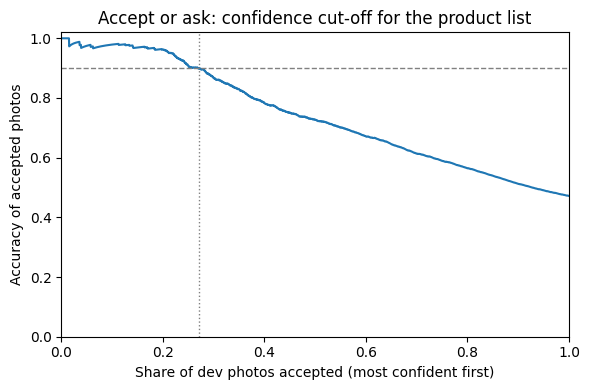

In [10]:
import copy
from scipy.optimize import minimize_scalar
from scipy.special import log_softmax, softmax


def adabn(m, df):
    # Re-estimate BatchNorm running statistics on df (labels unused); weights stay fixed.
    m2 = copy.deepcopy(m)
    for mod in m2.modules():
        if isinstance(mod, nn.BatchNorm2d):
            mod.reset_running_stats()
            mod.momentum = None          # cumulative average over all batches
    m2.train()
    with torch.no_grad():
        for x, _ in loader(df, eval_tf, False):
            m2(x.to(device, non_blocking=True))
    return m2.eval()


def acc_on(m, df):
    return float((predict(m, loader(df, eval_tf, False)).argmax(1).numpy() == df["y"].to_numpy()).mean())


def fit_temperature(logits, y):
    def nll(logt):
        return -log_softmax(logits / np.exp(logt), axis=1)[np.arange(len(y)), y].mean()
    return float(np.exp(minimize_scalar(nll, bounds=(-3, 3), method="bounded").x))


def ece(probs, y, bins=15):
    conf, pred = probs.max(1), probs.argmax(1)
    edges = np.linspace(0, 1, bins + 1)
    e = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            e += m.mean() * abs((pred[m] == y[m]).mean() - conf[m].mean())
    return float(e)


def confidence_threshold(probs, y, target):
    # Smallest confidence cut-off whose accepted predictions reach the target accuracy.
    conf, ok = probs.max(1), probs.argmax(1) == y
    order = np.argsort(-conf)
    run_acc = np.cumsum(ok[order]) / np.arange(1, len(ok) + 1)
    good = np.where(run_acc >= target)[0]
    if len(good) == 0:
        return 1.0, 0.0
    i = good.max()
    return float(conf[order][i]), float((i + 1) / len(ok))


# --- AdaBN, cross-fold test on dev bursts ---
fold_of = {}
for c, g in real_dev.groupby("cls"):
    for j, b in enumerate(sorted(g["burst"].unique())):
        fold_of[b] = j % 2
dev_fold = real_dev["burst"].map(fold_of)
base_accs, ada_accs = [], []
for f in (0, 1):
    adapt_df, eval_df = real_dev[dev_fold == f], real_dev[dev_fold != f]
    if len(adapt_df) == 0 or len(eval_df) == 0:
        continue
    base_accs.append(acc_on(model, eval_df))
    ada_accs.append(acc_on(adabn(model, adapt_df), eval_df))
gain = float(np.mean(ada_accs) - np.mean(base_accs)) if base_accs else float("nan")
USE_ADABN = (ADABN == "1") or (ADABN == "auto" and gain >= ADABN_MIN_GAIN)
print(f"AdaBN cross-fold dev accuracy: {np.mean(base_accs):.4f} -> {np.mean(ada_accs):.4f} "
      f"(gain {gain:+.4f}) | kept: {USE_ADABN}")
if USE_ADABN:
    model = adabn(model, real_dev)
    torch.save(model.state_dict(), MODEL_DIR / "final_adabn.pt")

# --- Temperature scaling and the app's confidence cut-off ---
logits_dev = predict(model, dl_dev).numpy().astype(np.float64)
y_dev = real_dev["y"].to_numpy()
TEMP = fit_temperature(logits_dev, y_dev)
p_raw, p_cal = softmax(logits_dev, axis=1), softmax(logits_dev / TEMP, axis=1)
CONF_T, coverage = confidence_threshold(p_cal, y_dev, CONF_TARGET)
calib = {
    "run_name": RUN_NAME, "aug_v2": AUG_V2,
    "adabn_crossfold_dev_acc_before": float(np.mean(base_accs)) if base_accs else None,
    "adabn_crossfold_dev_acc_after": float(np.mean(ada_accs)) if ada_accs else None,
    "adabn_gain": gain, "adabn_used": bool(USE_ADABN),
    "real_dev_acc_final_model": float((p_cal.argmax(1) == y_dev).mean()),
    "temperature": TEMP,
    "dev_ece_before": ece(p_raw, y_dev), "dev_ece_after": ece(p_cal, y_dev),
    "confidence_threshold": CONF_T, "conf_target": CONF_TARGET,
    "dev_coverage_at_threshold": coverage,
}
print(json.dumps(calib, indent=2))
(OUT / "calibration.json").write_text(json.dumps(calib, indent=2))

# Coverage-accuracy curve: what share of photos the app can accept at each accuracy level
conf, ok = p_cal.max(1), p_cal.argmax(1) == y_dev
order = np.argsort(-conf)
cov_ = np.arange(1, len(ok) + 1) / len(ok)
acc_ = np.cumsum(ok[order]) / np.arange(1, len(ok) + 1)
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(cov_, acc_)
ax.axhline(CONF_TARGET, ls="--", c="gray", lw=1)
ax.axvline(coverage, ls=":", c="gray", lw=1)
ax.set_xlabel("Share of dev photos accepted (most confident first)")
ax.set_ylabel("Accuracy of accepted photos")
ax.set_ylim(0, 1.02); ax.set_xlim(0, 1)
ax.set_title("Accept or ask: confidence cut-off for the product list")
fig.tight_layout(); fig.savefig(FIG_DIR / "coverage_accuracy.png", dpi=150); plt.show()

# With team photos, app photos resemble them more than the 300 x 135 Capsure frames: refit on team-dev.
# Team-dev is about 120 photos from 20 sessions, so treat the cut-off as approximate.
if HAVE_TEAM and len(team_dev) >= 20:
    lt_ = predict(model, loader(team_dev, eval_tf, False)).numpy().astype(np.float64)
    yt_ = team_dev["y"].astype(int).to_numpy()
    TEMP = fit_temperature(lt_, yt_)
    CONF_T, cov_team = confidence_threshold(softmax(lt_ / TEMP, axis=1), yt_, CONF_TARGET)
    calib.update({"calibrated_on": "team_dev", "temperature": TEMP, "confidence_threshold": CONF_T,
                  "team_dev_coverage_at_threshold": cov_team, "team_dev_ece_after": ece(softmax(lt_ / TEMP, axis=1), yt_)})
    print(f"Recalibrated on team-dev: T={TEMP:.3f}, cut-off={CONF_T:.3f}, coverage={cov_team:.3f}")
    (OUT / "calibration.json").write_text(json.dumps(calib, indent=2))

## 7. Test on held-out real bursts

Reported three ways: per frame, per near-duplicate cluster (one frame per cluster), and per burst (majority vote). The burst level is the honest sample size for confidence intervals.

/tmp/ipykernel_23/1624144590.py:15: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  per_class = T_.groupby("cls").apply(lambda g: float((g["p"] == g["y"]).mean())).to_dict()


{
  "best_epoch": 8,
  "synthetic_val_accuracy": 0.981,
  "real_test_frame_accuracy": 0.4951856946354883,
  "real_test_macro_f1": 0.5076558989383604,
  "real_test_cluster_accuracy": 0.5456228510975932,
  "n_clusters": 3781,
  "real_test_burst_accuracy": 0.5559322033898305,
  "n_bursts": 295,
  "real_test_burst_accuracy_wilson95": [
    0.4988745419807309,
    0.6115518511318746
  ],
  "lighting_only_baseline_burst_accuracy": 0.14133333333333334
}


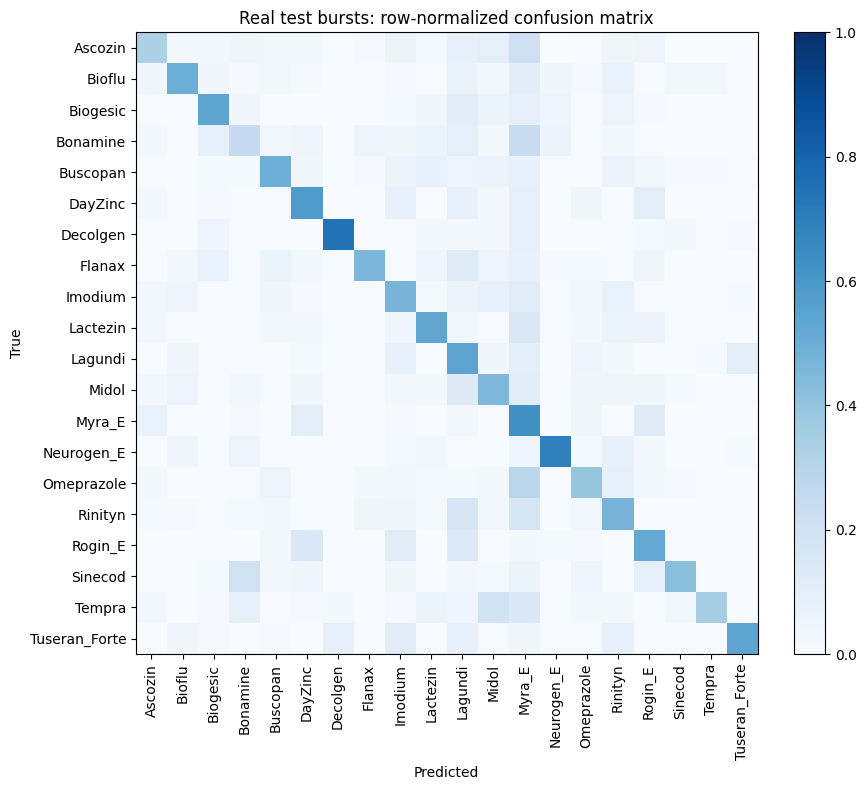

In [11]:
from sklearn.metrics import f1_score, confusion_matrix

dl_test = loader(real_test, eval_tf, False)
logits_test = predict(model, dl_test)
p_test = logits_test.argmax(1).numpy()
y_test = real_test["y"].to_numpy()

frame_acc = float((p_test == y_test).mean())
macro_f1 = float(f1_score(y_test, p_test, average="macro"))
T_ = real_test.assign(p=p_test)
clus = T_.groupby("dup_cluster").first()
clus_k, clus_n = int((clus["p"] == clus["y"]).sum()), len(clus)
bv_ = T_.groupby("burst").agg(y=("y", "first"), p=("p", lambda s: s.mode().iloc[0]))
bk_, bn_ = int((bv_["p"] == bv_["y"]).sum()), len(bv_)
per_class = T_.groupby("cls").apply(lambda g: float((g["p"] == g["y"]).mean())).to_dict()

syn_val_acc = float((predict(model, dl_synval).argmax(1).numpy() == syn_val["y"].to_numpy()).mean())
metrics = {
    "best_epoch": best[1],
    "synthetic_val_accuracy": syn_val_acc,
    "real_test_frame_accuracy": frame_acc,
    "real_test_macro_f1": macro_f1,
    "real_test_cluster_accuracy": clus_k / clus_n, "n_clusters": clus_n,
    "real_test_burst_accuracy": bk_ / bn_, "n_bursts": bn_,
    "real_test_burst_accuracy_wilson95": wilson(bk_, bn_),
    "per_class_frame_accuracy": per_class,
    "lighting_only_baseline_burst_accuracy": lighting["burst_accuracy"],
}
print(json.dumps({k: v for k, v in metrics.items() if k != "per_class_frame_accuracy"}, indent=2))

cm = confusion_matrix(y_test, p_test, labels=range(C), normalize="true")
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(cm, vmin=0, vmax=1, cmap="Blues")
ax.set_xticks(range(C)); ax.set_xticklabels(CLASSES, rotation=90)
ax.set_yticks(range(C)); ax.set_yticklabels(CLASSES)
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
ax.set_title("Real test bursts: row-normalized confusion matrix")
fig.colorbar(im, ax=ax, fraction=0.046)
fig.tight_layout(); fig.savefig(FIG_DIR / "confusion_matrix.png", dpi=150); plt.show()

## 8. Out-of-scope guard: Mahalanobis score with a conformal threshold

1. Take 512-d penultimate features of synthetic training images; fit one mean per class and one shared covariance (Lee et al., 2018).
2. Score an image by its smallest Mahalanobis distance to any class mean, then standardize it with that class's mean and spread on synthetic validation images.
3. Threshold: with n calibration scores (one frame per dev burst), take the k-th smallest, k = ⌈(n+1)(1−α)⌉. This bounds the rate of wrongly rejected in-scope photos at α for photos taken like the calibration set (Bates et al., 2023). It needs n ≥ 1/α − 1 = 19.

In [12]:
backbone = nn.Sequential(*list(model.children())[:-1], nn.Flatten(1)).eval()


@torch.no_grad()
def features(df):
    out = []
    for x, _ in loader(df, eval_tf, False):
        out.append(backbone(x.to(device)).float().cpu())
    return torch.cat(out).numpy().astype(np.float64)


fit_df = syn_train.groupby("cls", group_keys=False).apply(
    lambda g: g.sample(min(len(g), FEATS_PER_CLASS), random_state=SEED))
F_fit = features(fit_df)
y_fit = fit_df["y"].to_numpy()
mu = np.stack([F_fit[y_fit == c].mean(0) for c in range(C)])
centered = F_fit - mu[y_fit]
cov = centered.T @ centered / len(F_fit)
cov += np.eye(cov.shape[0]) * 1e-6 * np.trace(cov) / cov.shape[0]
prec = np.linalg.inv(cov)


def maha(Fm):
    d = np.stack([np.einsum("nd,de,ne->n", Fm - mu[c], prec, Fm - mu[c]) for c in range(C)], 1)
    return d.min(1), d.argmin(1)


s_val, c_val = maha(features(syn_val))
glob_m, glob_s = s_val.mean(), s_val.std() + 1e-9
m_c = np.array([s_val[c_val == c].mean() if (c_val == c).sum() >= 10 else glob_m for c in range(C)])
sd_c = np.array([s_val[c_val == c].std() + 1e-9 if (c_val == c).sum() >= 10 else glob_s for c in range(C)])


def zscore(Fm):
    s, c = maha(Fm)
    return (s - m_c[c]) / sd_c[c]


cal = meta[meta.is_cal]
if HAVE_TEAM and GUARD_CAL == "pooled" and len(team_dev):
    # Add one team-dev photo per session so the threshold also reflects phone photos like the app's.
    cal = pd.concat([cal[["cache", "y"]], team_dev.groupby("group").sample(1, random_state=SEED)[["cache", "y"]]],
                    ignore_index=True)
    print(f"Guard calibration pool: {len(cal)} photos (Capsure dev bursts + one team-dev photo per session)")
z_cal = np.sort(zscore(features(cal)))
n_cal = len(z_cal)
k = math.ceil((n_cal + 1) * (1 - ALPHA))
if k > n_cal:
    print(f"WARNING: n_cal={n_cal} is too small for alpha={ALPHA}; threshold set to the max score.")
    k = n_cal
thr = float(z_cal[k - 1])

z_test = zscore(features(real_test))
rej = z_test > thr
T_ = T_.assign(z=z_test, rejected=rej)
one_per_burst = T_.groupby("burst").sample(1, random_state=SEED)
fr_k, fr_n = int(one_per_burst["rejected"].sum()), len(one_per_burst)
guard = {
    "alpha": ALPHA, "n_cal": n_cal, "k": k, "threshold_z": thr,
    "false_rejection_all_test_frames": float(rej.mean()),
    "false_rejection_one_frame_per_burst": fr_k / fr_n, "n_bursts": fr_n,
    "false_rejection_one_frame_per_burst_wilson95": wilson(fr_k, fr_n),
}

ood_files = [p for p in Path(OOD_DIR).rglob("*") if p.suffix.lower() in IMG_EXT] if OOD_DIR and Path(OOD_DIR).exists() else []
if ood_files:
    from sklearn.metrics import roc_auc_score
    ood_cache = []
    for i, p in enumerate(ood_files):
        dst = CACHE_DIR / "ood" / f"{i:06d}.jpg"
        process((str(p), str(dst), False))
        ood_cache.append(str(dst))
    ood_df = pd.DataFrame({"cache": ood_cache, "y": 0})
    z_ood = zscore(features(ood_df))
    labels = np.r_[np.zeros(len(one_per_burst)), np.ones(len(z_ood))]
    scores = np.r_[one_per_burst["z"].to_numpy(), z_ood]
    guard.update({"ood_n": len(z_ood), "ood_auroc_vs_one_frame_per_test_burst": float(roc_auc_score(labels, scores)),
                  "ood_detected_at_threshold": float((z_ood > thr).mean())})
else:
    print("No OOD_DIR given: AUROC against out-of-scope medicines is skipped.")
metrics["ood_guard"] = guard
print(json.dumps(guard, indent=2))
(OUT / "metrics.json").write_text(json.dumps(metrics, indent=2, default=float))

/tmp/ipykernel_23/4057538587.py:12: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  fit_df = syn_train.groupby("cls", group_keys=False).apply(


No OOD_DIR given: AUROC against out-of-scope medicines is skipped.
{
  "alpha": 0.05,
  "n_cal": 80,
  "k": 77,
  "threshold_z": 4.900321728016332,
  "false_rejection_all_test_frames": 0.03404401650618982,
  "false_rejection_one_frame_per_burst": 0.013559322033898305,
  "n_bursts": 295,
  "false_rejection_one_frame_per_burst_wilson95": [
    0.005285166317945109,
    0.03433983903606183
  ]
}


1560

## 8b. Is the out-of-scope guard effective?

The guard has two jobs: keep wrongly rejected in-scope photos at about α = 5%, and catch photos of medicines outside the 20 products. This cell tests both, against targets fixed before the run.

**In-scope set:** one frame per real test burst (the burst is the honest sample size).

**Out-of-scope sources** (each scored and reported separately):
1. every folder in `SC_OOD_DIR` / `SC_OOD_DIRS`;
2. with `OOD_AUTO`, every other dataset attached to this notebook (for example the V1 loose-pill dataset or the CapCure sets), up to `OOD_MAX_PER_SOURCE` random images each. Do not attach team photos of the 20 products while this is on, or they will be counted as out-of-scope; use `SC_OOD_EXCLUDE` to skip a dataset by name;
3. a **class-holdout test** that needs no extra data: 5 of the 20 products are hidden from the guard (their class means are removed), and their real test photos act as unknown medicines. This is optimistic, because the network itself was trained on those products, so it is a ceiling, not a final result.

**Baselines.** The Mahalanobis score must beat two simpler scores computed from the same network: maximum softmax probability (Hendrycks & Gimpel, 2017) and the energy score (Liu et al., 2020). If it does not, the extra machinery adds nothing.

**Verdict rules (pre-registered):**
- false rejection on test bursts ≤ α (point estimate), with its Wilson 95% interval reported;
- AUROC ≥ `AUROC_TARGET` on every real out-of-scope source, with a bootstrap 95% interval;
- Mahalanobis AUROC above both baselines on that source.

`EFFECTIVE` means all rules pass on every real source; `PARTIAL` means some pass; `NOT EFFECTIVE` means none pass; `NOT TESTED` means no real out-of-scope source was attached (the class-holdout ceiling is still reported).

Out-of-scope sources found: none

GUARD VERDICT: NOT TESTED
 - No real out-of-scope source attached; only the class-holdout ceiling is available.
{
  "median_z_synthetic_val": -0.2317351212044036,
  "median_z_real_calibration": 2.0409494804398545,
  "median_z_real_test": 2.1815888872127545,
  "threshold_z": 4.900321728016332
}


/tmp/ipykernel_23/1131652493.py:194: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[1].legend(fontsize=8); axes[1].set_title("ROC per out-of-scope source")


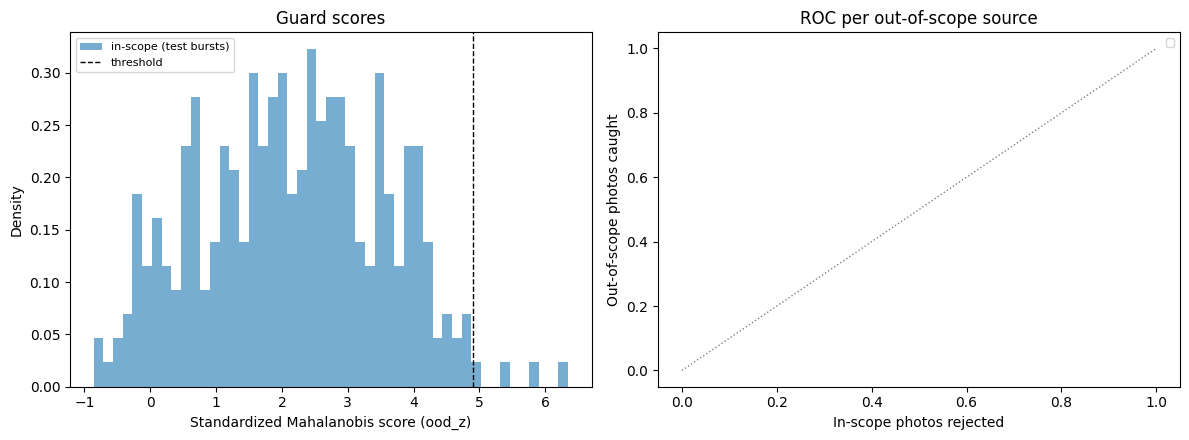

2650

In [13]:
from sklearn.metrics import roc_auc_score, roc_curve


def find_ood_sources():
    # Map source name -> folder. Explicit folders first, then other attached datasets.
    srcs = {}
    for d in ([OOD_DIR] if OOD_DIR else []) + OOD_DIRS:
        if Path(d).exists():
            srcs[Path(d).name] = Path(d)
        else:
            print("OOD folder not found:", d)
    base = Path("/kaggle/input")
    if OOD_AUTO and base.exists():
        roots = []
        for c in sorted(p for p in base.iterdir() if p.is_dir()):
            if c.name in {"datasets", "competitions", "models", "notebooks", "kernels"}:
                # Newer mount layout: /kaggle/input/datasets/<owner>/<slug>
                for owner in sorted(p for p in c.iterdir() if p.is_dir()):
                    roots += sorted(p for p in owner.iterdir() if p.is_dir())
            else:
                roots.append(c)
        for r in roots:
            if ROOT.resolve().is_relative_to(r.resolve()):
                continue   # the Capsure dataset itself
            if HAVE_TEAM and (Path(TEAM_DIR).is_relative_to(r) or Path(TEAM_DIR).resolve().is_relative_to(r.resolve())):
                continue   # team photos are in-scope, never out-of-scope
            if any(x.lower() in str(r).lower() for x in OOD_EXCLUDE):
                continue
            if r.name.startswith("models") or "/models/" in str(r):
                continue
            srcs.setdefault(r.name, r)
    return srcs


def list_images(folder, cap, seed=SEED):
    files = sorted(p for p in Path(folder).rglob("*") if p.suffix.lower() in IMG_EXT)
    if len(files) > cap:
        files = [files[i] for i in np.random.default_rng(seed).choice(len(files), cap, replace=False)]
    return files


def class_name_overlap(folder):
    # Folder names that match one of the 20 products: a warning that the source may not be out-of-scope.
    names = {p.name.lower() for p in Path(folder).rglob("*") if p.is_dir()}
    return sorted(c for c in CLASSES if c.lower() in names)


def boot_auroc(neg, pos, n_boot=1000, seed=SEED):
    r = np.random.default_rng(seed)
    labels = np.r_[np.zeros(len(neg)), np.ones(len(pos))]
    point = float(roc_auc_score(labels, np.r_[neg, pos]))
    bs = []
    for _ in range(n_boot):
        a = neg[r.integers(0, len(neg), len(neg))]
        b = pos[r.integers(0, len(pos), len(pos))]
        bs.append(roc_auc_score(labels, np.r_[a, b]))
    lo, hi = np.percentile(bs, [2.5, 97.5])
    return point, float(lo), float(hi)


def fpr_at_95_detect(neg, pos):
    # Share of in-scope photos rejected when the cut-off catches 95% of out-of-scope photos.
    cut = np.quantile(pos, 0.05)
    return float((neg >= cut).mean())


def verdict(guard_fr, source_results, alpha=ALPHA, target=AUROC_TARGET):
    real = {k: v for k, v in source_results.items() if not k.startswith("class_holdout")}
    if not real:
        return "NOT TESTED", ["No real out-of-scope source attached; only the class-holdout ceiling is available."]
    notes, passes = [], []
    fr_ok = guard_fr <= alpha
    notes.append(f"False rejection {guard_fr:.3f} vs alpha {alpha}: {'pass' if fr_ok else 'FAIL'}")
    for k, v in real.items():
        a_ok = v["auroc_mahalanobis"] >= target
        b_ok = v["auroc_mahalanobis"] > max(v["auroc_msp"], v["auroc_energy"])
        passes.append(fr_ok and a_ok and b_ok)
        notes.append(f"{k}: AUROC {v['auroc_mahalanobis']:.3f} (95% CI {v['auroc_ci95'][0]:.3f} to {v['auroc_ci95'][1]:.3f}) "
                     f"target {'pass' if a_ok else 'FAIL'}; beats MSP {v['auroc_msp']:.3f} and energy "
                     f"{v['auroc_energy']:.3f}: {'yes' if b_ok else 'NO'}")
    if all(passes):
        return "EFFECTIVE", notes
    if any(passes):
        return "PARTIAL", notes
    return "NOT EFFECTIVE", notes


def all_scores(df_or_feats):
    Fm = features(df_or_feats) if isinstance(df_or_feats, pd.DataFrame) else df_or_feats
    with torch.no_grad():
        lg = model.fc(torch.tensor(Fm, dtype=torch.float32, device=device)).cpu().numpy().astype(np.float64)
    lg = lg / TEMP
    msp = -softmax(lg, axis=1).max(1)                      # higher = more out-of-scope
    lse = np.log(np.exp(lg - lg.max(1, keepdims=True)).sum(1)) + lg.max(1)
    energy = -TEMP * lse                                   # higher = more out-of-scope
    return {"maha": zscore(Fm), "msp": msp, "energy": energy}, Fm


# In-scope reference: one frame per test burst
in_df = real_test.loc[one_per_burst.index]
S_in, F_in = all_scores(in_df)
guard_fr = float((S_in["maha"] > thr).mean())

# Domain diagnostic: where do the scores sit?
diag = {"median_z_synthetic_val": float(np.median(zscore(features(syn_val.sample(min(2000, len(syn_val)), random_state=SEED))))),
        "median_z_real_calibration": float(np.median(z_cal)),
        "median_z_real_test": float(np.median(S_in["maha"])),
        "threshold_z": thr}

source_results, ood_scores = {}, {}
srcs = find_ood_sources()
print("Out-of-scope sources found:", {k: str(v) for k, v in srcs.items()} or "none")
for name, folder in srcs.items():
    files = list_images(folder, OOD_MAX_PER_SOURCE)
    if len(files) < 20:
        print(f"Skipping {name}: only {len(files)} images")
        continue
    overlap = class_name_overlap(folder)
    if overlap:
        print(f"WARNING {name}: folders named like in-scope products {overlap}. "
              "If these are packs of the 20 products, exclude this source.")
    jobs = [(str(p), str(CACHE_DIR / "ood_eval" / name / f"{i:06d}.jpg"), False) for i, p in enumerate(files)]
    # Threads, not forked processes: CUDA is already initialized at this point.
    from concurrent.futures import ThreadPoolExecutor
    with ThreadPoolExecutor(max_workers=NUM_WORKERS) as ex:
        list(ex.map(process, jobs))
    S_o, _ = all_scores(pd.DataFrame({"cache": [j[1] for j in jobs], "y": 0}))
    auc, lo, hi = boot_auroc(S_in["maha"], S_o["maha"])
    source_results[name] = {
        "n_images": len(files), "folder": str(folder), "in_scope_name_overlap": overlap,
        "auroc_mahalanobis": auc, "auroc_ci95": [lo, hi],
        "auroc_msp": float(roc_auc_score(np.r_[np.zeros(len(S_in['msp'])), np.ones(len(S_o['msp']))], np.r_[S_in["msp"], S_o["msp"]])),
        "auroc_energy": float(roc_auc_score(np.r_[np.zeros(len(S_in['energy'])), np.ones(len(S_o['energy']))], np.r_[S_in["energy"], S_o["energy"]])),
        "detected_at_threshold": float((S_o["maha"] > thr).mean()),
        "in_scope_rejected_at_95pct_detection": fpr_at_95_detect(S_in["maha"], S_o["maha"]),
        "median_z": float(np.median(S_o["maha"])),
    }
    ood_scores[name] = S_o["maha"]

# Class-holdout ceiling (no extra data): hide 5 products at a time from the guard
y_in = in_df["y"].to_numpy()
perm = np.random.default_rng(SEED).permutation(C)
ho_aucs = []
for f in range(4):
    hidden = perm[f * 5:(f + 1) * 5]
    keep = np.setdiff1d(np.arange(C), hidden)
    mu_k = np.stack([F_fit[y_fit == c].mean(0) for c in keep])
    m_fit = np.isin(y_fit, keep)
    cen = F_fit[m_fit] - mu_k[np.searchsorted(keep, y_fit[m_fit])]
    cov_k = cen.T @ cen / len(cen)
    cov_k += np.eye(cov_k.shape[0]) * 1e-6 * np.trace(cov_k) / cov_k.shape[0]
    prec_k = np.linalg.inv(cov_k)
    d = np.stack([np.einsum("nd,de,ne->n", F_in - m, prec_k, F_in - m) for m in mu_k], 1).min(1)
    is_out = np.isin(y_in, hidden)
    if is_out.any() and (~is_out).any():
        ho_aucs.append(float(roc_auc_score(is_out.astype(int), d)))
if ho_aucs:
    source_results["class_holdout_ceiling"] = {"auroc_mahalanobis_mean": float(np.mean(ho_aucs)),
                                               "auroc_per_fold": ho_aucs,
                                               "note": "optimistic: the network was trained on the hidden products"}

v, notes = verdict(guard_fr, source_results)
guard_eval = {
    "run_name": RUN_NAME, "verdict": v, "notes": notes,
    "false_rejection_one_frame_per_test_burst": guard_fr,
    "false_rejection_wilson95": wilson(int((S_in["maha"] > thr).sum()), len(S_in["maha"])),
    "n_test_bursts": int(len(S_in["maha"])),
    "auroc_msp_and_energy_note": "baselines use the same network and temperature",
    "diagnostic": diag, "sources": source_results,
}
print("\nGUARD VERDICT:", v)
for n_ in notes:
    print(" -", n_)
print(json.dumps(diag, indent=2))
(OUT / "guard_eval.json").write_text(json.dumps(guard_eval, indent=2, default=float))
metrics["guard_eval"] = guard_eval
(OUT / "metrics.json").write_text(json.dumps(metrics, indent=2, default=float))

# Figures: score distributions and ROC curves
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
bins = np.linspace(min([S_in["maha"].min()] + [s.min() for s in ood_scores.values()]),
                   max([S_in["maha"].max()] + [s.max() for s in ood_scores.values()]), 50)
axes[0].hist(S_in["maha"], bins=bins, density=True, alpha=0.6, label="in-scope (test bursts)")
for name, s in ood_scores.items():
    axes[0].hist(s, bins=bins, density=True, alpha=0.4, label=name[:30])
axes[0].axvline(thr, c="k", ls="--", lw=1, label="threshold")
axes[0].set_xlabel("Standardized Mahalanobis score (ood_z)"); axes[0].set_ylabel("Density")
axes[0].legend(fontsize=8); axes[0].set_title("Guard scores")
for name, s in ood_scores.items():
    fpr, tpr, _ = roc_curve(np.r_[np.zeros(len(S_in["maha"])), np.ones(len(s))], np.r_[S_in["maha"], s])
    axes[1].plot(fpr, tpr, label=f"{name[:30]} (AUROC {source_results[name]['auroc_mahalanobis']:.2f})")
axes[1].plot([0, 1], [0, 1], c="gray", lw=1, ls=":")
axes[1].set_xlabel("In-scope photos rejected"); axes[1].set_ylabel("Out-of-scope photos caught")
axes[1].legend(fontsize=8); axes[1].set_title("ROC per out-of-scope source")
fig.tight_layout(); fig.savefig(FIG_DIR / "guard_eval.png", dpi=150); plt.show()

# Phone photos of in-scope packs (team-test): how many does the guard wrongly reject?
if HAVE_TEAM and len(team_test):
    zt_ = zscore(features(team_test))
    one_t = team_test.assign(z=zt_).groupby("group").sample(1, random_state=SEED)
    k_t, n_t = int((one_t["z"] > thr).sum()), len(one_t)
    guard_eval.update({"false_rejection_team_test_one_per_session": k_t / n_t,
                       "false_rejection_team_test_wilson95": wilson(k_t, n_t),
                       "false_rejection_team_test_all_photos": float((zt_ > thr).mean())})
    print(f"Guard false rejection on team-test phone photos: {k_t}/{n_t} sessions, "
          f"{float((zt_ > thr).mean()):.3f} of all photos")
metrics["finetune"] = FT_REPORT
(OUT / "guard_eval.json").write_text(json.dumps(guard_eval, indent=2, default=float))
(OUT / "metrics.json").write_text(json.dumps(metrics, indent=2, default=float))

## 9. Export to ONNX for the Android app

One file, two outputs:
- `logits` (1 × 20): product scores, order given in `labels.json`;
- `ood_z` (1): standardized out-of-scope score; reject the product ID when `ood_z > threshold_z` from `meta.json`.

Input: `image`, float32, shape 1 × 3 × 224 × 224, RGB scaled to 0..1, after EXIF rotation and letterboxing to a square with the fill color in `meta.json`. ImageNet normalization happens inside the model.

In [14]:
class SureCureNet(nn.Module):
    def __init__(self, model):
        super().__init__()
        self.backbone = nn.Sequential(*list(model.children())[:-1], nn.Flatten(1))
        self.fc = model.fc
        self.register_buffer("img_mean", torch.tensor(MEAN).view(1, 3, 1, 1))
        self.register_buffer("img_std", torch.tensor(STD).view(1, 3, 1, 1))
        self.register_buffer("mu", torch.tensor(mu, dtype=torch.float32))
        self.register_buffer("prec", torch.tensor(prec, dtype=torch.float32))
        self.register_buffer("m_c", torch.tensor(m_c, dtype=torch.float32))
        self.register_buffer("sd_c", torch.tensor(sd_c, dtype=torch.float32))

    def forward(self, x):
        f = self.backbone((x - self.img_mean) / self.img_std)
        logits = self.fc(f)
        diff = f.unsqueeze(1) - self.mu.unsqueeze(0)            # B x C x D
        d = (torch.matmul(diff, self.prec) * diff).sum(-1)      # B x C
        s, c = torch.min(d, dim=1)
        z = (s - self.m_c[c]) / self.sd_c[c]
        return logits, z


net = SureCureNet(model).float().cpu().eval()
dummy = torch.rand(1, 3, IMG, IMG)
onnx_path = MODEL_DIR / "surecure.onnx"
export_kwargs = dict(input_names=["image"], output_names=["logits", "ood_z"],
                     dynamic_axes={"image": {0: "batch"}, "logits": {0: "batch"}, "ood_z": {0: "batch"}},
                     opset_version=17)
import inspect
if "dynamo" in inspect.signature(torch.onnx.export).parameters:
    export_kwargs["dynamo"] = False   # classic exporter: stable for this graph
torch.onnx.export(net, dummy, str(onnx_path), **export_kwargs)
print("Saved", onnx_path, f"{onnx_path.stat().st_size / 1e6:.1f} MB")

(MODEL_DIR / "labels.json").write_text(json.dumps(CLASSES, indent=2))
(MODEL_DIR / "meta.json").write_text(json.dumps({
    "input": {"name": "image", "shape": [1, 3, IMG, IMG], "dtype": "float32", "range": [0, 1], "channels": "RGB",
              "preprocess": "EXIF rotate upright, letterbox to square with fill_rgb, resize to 224x224 bilinear, divide by 255"},
    "fill_rgb": list(FILL),
    "outputs": {"logits": "product scores in labels.json order", "ood_z": "reject product ID if ood_z > threshold_z"},
    "threshold_z": thr, "alpha": ALPHA, "n_cal": n_cal,
    "best_epoch": best[1], "seed": SEED,
    "run_name": RUN_NAME, "aug_v2": AUG_V2, "adabn_used": bool(USE_ADABN),
    "temperature": TEMP, "confidence_threshold": CONF_T,
    "confidence_rule": "show the product list if max(softmax(logits / temperature)) < confidence_threshold",
    "guard_verdict": guard_eval["verdict"],
    "finetuned_on_team_photos": bool(FT_REPORT.get("used", False)),
}, indent=2))

/tmp/ipykernel_23/3824202700.py:32: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(net, dummy, str(onnx_path), **export_kwargs)


Saved /kaggle/working/surecure_model/surecure.onnx 45.8 MB


919

In [15]:
# Parity check: ONNX Runtime must reproduce PyTorch outputs.
try:
    import onnxruntime as ort
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "onnxruntime"], check=True)
    import onnxruntime as ort

sess = ort.InferenceSession(str(onnx_path), providers=["CPUExecutionProvider"])
sample = real_test.sample(min(64, len(real_test)), random_state=SEED)
x = torch.stack([T.Compose([T.Resize((IMG, IMG)), T.ToTensor()])(Image.open(p).convert("RGB")) for p in sample["cache"]])
with torch.no_grad():
    lt, zt = net(x)
lo, zo = sess.run(None, {"image": x.numpy()})
dl, dz = float(np.abs(lo - lt.numpy()).max()), float(np.abs(zo - zt.numpy()).max())
print(f"max |logits diff| = {dl:.2e}, max |ood_z diff| = {dz:.2e}")
agree = float((lo.argmax(1) == lt.numpy().argmax(1)).mean())
print("Top-1 agreement:", agree)
assert agree >= 0.98 and dl < 1e-2, "ONNX and PyTorch outputs differ more than expected"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 82.2 MB/s eta 0:00:00
max |logits diff| = 9.54e-06, max |ood_z diff| = 5.72e-06
Top-1 agreement: 1.0


### 9b. Golden test images for the Kotlin app

The most common silent failure in a phone app is preprocessing that differs from training: a skipped EXIF rotation, BGR instead of RGB, stretching instead of letterboxing, or 0..255 instead of 0..1. Nothing crashes; accuracy just drops. This cell exports `GOLDEN_N` real test photos (one per product) with the outputs the app must reproduce:

- `golden/raw/`: the original files, still sideways with their EXIF flag, exactly as a phone would load them;
- `golden/tensor_XX.bin`: the 1 × 3 × 224 × 224 float32 input (little-endian, RGB, 0..1) after the app pipeline: EXIF upright, letterbox with `fill_rgb`, bilinear resize to 224;
- `golden/expected.json`: expected `logits`, `ood_z`, calibrated confidence and top-1 label.

Two tests for the app developer:
1. **Runtime test:** feed `tensor_XX.bin` straight into ONNX Runtime on the phone. Logits must match within 1e-3. This checks the model file and runtime only.
2. **Preprocessing test:** load `raw/XX_*` through the Kotlin pipeline. Top-1 must match on all files and logits should be within about 0.1 (Android and PIL bilinear resizing differ slightly). A wrong top-1 means a preprocessing bug.

In [16]:
GOLDEN_DIR = OUT / "golden"
(GOLDEN_DIR / "raw").mkdir(parents=True, exist_ok=True)


def app_preprocess(path):
    # Mirrors the app: EXIF upright -> RGB -> letterbox with FILL -> 224 bilinear -> 0..1, CHW
    img = ImageOps.exif_transpose(Image.open(path)).convert("RGB")
    img = letterbox(img).resize((IMG, IMG), Image.BILINEAR)
    return np.asarray(img, dtype=np.float32).transpose(2, 0, 1)[None] / 255.0


pick = (real_test.groupby("cls", group_keys=False).apply(lambda g: g.sample(1, random_state=SEED))
        .head(GOLDEN_N))
golden = []
for i, (_, r) in enumerate(pick.iterrows()):
    x_app = app_preprocess(r["path"]).astype(np.float32)
    x_app.astype("<f4").tofile(GOLDEN_DIR / f"tensor_{i:02d}.bin")
    raw_name = f"{i:02d}_{r['cls']}{Path(r['path']).suffix.lower()}"
    shutil.copy(r["path"], GOLDEN_DIR / "raw" / raw_name)
    lo_, zo_ = sess.run(None, {"image": x_app})
    prob = softmax(lo_[0].astype(np.float64) / TEMP)
    golden.append({"index": i, "raw_file": f"raw/{raw_name}", "tensor_file": f"tensor_{i:02d}.bin",
                   "true_label": r["cls"], "expected_top1": CLASSES[int(lo_[0].argmax())],
                   "expected_logits": [float(v) for v in lo_[0]], "expected_ood_z": float(zo_[0]),
                   "expected_confidence": float(prob.max()),
                   "expected_accept": bool(prob.max() >= CONF_T and float(zo_[0]) <= thr)})
(GOLDEN_DIR / "expected.json").write_text(json.dumps({
    "input_layout": "float32 little-endian, shape 1x3x224x224, RGB, range 0..1",
    "tolerance_runtime_logits": 1e-3, "tolerance_preprocess_logits": 0.1,
    "labels": CLASSES, "temperature": TEMP, "confidence_threshold": CONF_T, "threshold_z": thr,
    "images": golden}, indent=2))
print(f"Exported {len(golden)} golden images to {GOLDEN_DIR}")

# Does the app pipeline (direct to 224) agree with the notebook pipeline (256 cache, then 224)?
chk = real_test.sample(min(300, len(real_test)), random_state=SEED)
xa = np.concatenate([app_preprocess(p) for p in chk["path"]]).astype(np.float32)
la, _ = sess.run(None, {"image": xa})
xn = torch.stack([T.Compose([T.Resize((IMG, IMG)), T.ToTensor()])(Image.open(p).convert("RGB")) for p in chk["cache"]]).numpy()
ln, _ = sess.run(None, {"image": xn})
pipe_agree = float((la.argmax(1) == ln.argmax(1)).mean())
print(f"Top-1 agreement, app pipeline vs notebook pipeline on {len(chk)} test frames: {pipe_agree:.3f}")
metrics["app_vs_notebook_pipeline_agreement"] = pipe_agree
(OUT / "metrics.json").write_text(json.dumps(metrics, indent=2, default=float))

/tmp/ipykernel_23/2785517815.py:12: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  pick = (real_test.groupby("cls", group_keys=False).apply(lambda g: g.sample(1, random_state=SEED))


Exported 10 golden images to /kaggle/working/golden
Top-1 agreement, app pipeline vs notebook pipeline on 300 test frames: 0.947


2710

## 10. Package outputs

In [17]:
zip_path = OUT / "surecure_outputs.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for p in [OUT / "metadata.csv", OUT / "audit.json", OUT / "lighting_baseline.json",
              OUT / "metrics.json", OUT / "history.csv"]:
        if p.exists():
            z.write(p, p.name)
    for d in (FIG_DIR, MODEL_DIR):
        for p in d.glob("*"):
            z.write(p, f"{d.name}/{p.name}")
    for p in [OUT / "calibration.json", OUT / "guard_eval.json"]:
        if p.exists():
            z.write(p, p.name)
    for p in [OUT / "finetune.json", OUT / "finetune_history.csv"]:
        if p.exists():
            z.write(p, p.name)
    for p in (OUT / "golden").rglob("*"):
        if p.is_file():
            z.write(p, str(p.relative_to(OUT)))
print("Download:", zip_path, f"{zip_path.stat().st_size / 1e6:.1f} MB")
shutil.rmtree(CACHE_DIR, ignore_errors=True)   # keep /kaggle/working small
if DRIVE_DIR:
    dst = Path(DRIVE_DIR) / RUN_NAME
    dst.mkdir(parents=True, exist_ok=True)
    shutil.copy(zip_path, dst / zip_path.name)
    print("Copied to Google Drive:", dst / zip_path.name)

Download: /kaggle/working/surecure_outputs.zip 86.7 MB


## References for the added cells

- Guo, C., Pleiss, G., Sun, Y., & Weinberger, K. Q. (2017). On calibration of modern neural networks. *Proceedings of the 34th International Conference on Machine Learning, 70*, 1321–1330. https://proceedings.mlr.press/v70/guo17a.html
- Hendrycks, D., & Gimpel, K. (2017). A baseline for detecting misclassified and out-of-distribution examples in neural networks. *International Conference on Learning Representations*. https://arxiv.org/abs/1610.02136
- Li, Y., Wang, N., Shi, J., Hou, X., & Liu, J. (2018). Adaptive batch normalization for practical domain adaptation. *Pattern Recognition, 80*, 109–117. https://doi.org/10.1016/j.patcog.2018.03.005
- Liu, W., Wang, X., Owens, J. D., & Li, Y. (2020). Energy-based out-of-distribution detection. *Advances in Neural Information Processing Systems, 33*, 21464–21475. https://arxiv.org/abs/2010.03759